<a href="https://colab.research.google.com/github/debad777/sjcu-test/blob/main/AI%EC%98%81%EC%83%81%EB%8D%B0%EC%9D%B4%ED%84%B0_7%EA%B0%958%EA%B0%95_%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습7_**이미지 분할**

# 01.1 컨투어 찾기
# 01.2 컨투어 그리기

In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('Gdrive',force_remount=True)

Mounted at Gdrive


[도형의 갯수] Contour:12


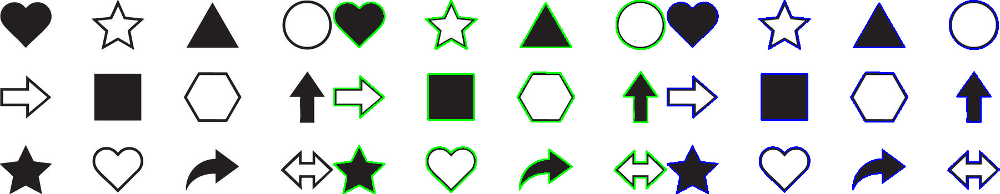

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


srcimg = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes-vector.jpg')
img1 = srcimg.copy()
img2 = srcimg.copy()

grayimg = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(grayimg, 127, 255, cv2.THRESH_BINARY_INV)


# 가장 바깥쪽 컨투어에 대해 파이썬 리스트 형태로 모든 좌표 반환: cv2.CHAIN_APPROX_NONE
contour, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(img1, contour, -1, (0,255,0), 2)


# 컨투어 모든 좌표를 파랑색 원으로 그리기
for i in contour:
    for j in i:
        cv2.circle(img2, tuple(j[0]), 1, (255,0,0), -1)


# 각각의 컨투의 갯수 출력
print('[도형의 갯수] Contour:%d'% (len(contour)))

image_frame = np.hstack([srcimg,img1,img2])
cv2_imshow(image_frame)

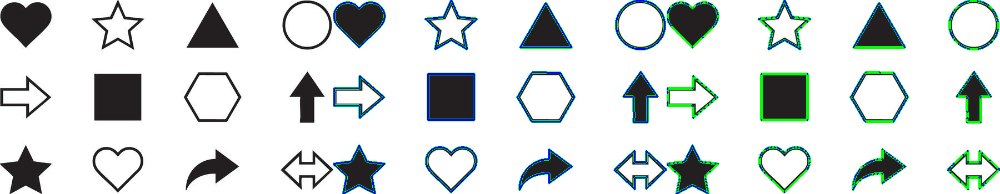

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


srcimg = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes-vector.jpg')
img1 = srcimg.copy()
img2 = srcimg.copy()

grayimg = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(grayimg, 127, 255, cv2.THRESH_BINARY_INV)


# 가장 바깥쪽 컨투어에 대해 파이썬 리스트 형태로 모든 좌표 반환: cv2.CHAIN_APPROX_NONE
contour1, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(img1, contour1, -1, (0,255,0), 4)
for i in contour1:
    for j in i:
        cv2.circle(img1, tuple(j[0]), 1, (255,0,0), -1)


# 가장 바깥쪽 컨투어에 대해 꼭지점 좌표만 반환: cv2.CHAIN_APPROX_SIMPLE
contour2, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(img2, contour2, -1, (0,255,0), 4)
for i in contour2:
    for j in i:
        cv2.circle(img2, tuple(j[0]), 1, (255,0,0), -1)


image_frame = np.hstack([srcimg,img1,img2])
cv2_imshow(image_frame)

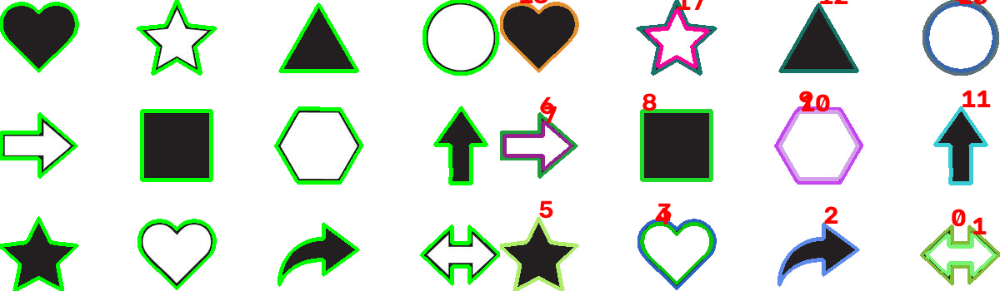

12 [Next, Prev, First Child, Parent]
[[[ 1 -1 -1 -1]
  [ 2  0 -1 -1]
  [ 3  1 -1 -1]
  [ 4  2 -1 -1]
  [ 5  3 -1 -1]
  [ 6  4 -1 -1]
  [ 7  5 -1 -1]
  [ 8  6 -1 -1]
  [ 9  7 -1 -1]
  [10  8 -1 -1]
  [11  9 -1 -1]
  [-1 10 -1 -1]]]
18 [Next, Prev, First Child, Parent]
[[[ 2 -1  1 -1]
  [-1 -1 -1  0]
  [ 3  0 -1 -1]
  [ 5  2  4 -1]
  [-1 -1 -1  3]
  [ 6  3 -1 -1]
  [ 8  5  7 -1]
  [-1 -1 -1  6]
  [ 9  6 -1 -1]
  [11  8 10 -1]
  [-1 -1 -1  9]
  [12  9 -1 -1]
  [13 11 -1 -1]
  [14 12 -1 -1]
  [16 13 15 -1]
  [-1 -1 -1 14]
  [-1 14 17 -1]
  [-1 -1 -1 16]]]


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

srcimg = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes-vector.jpg')
img1 = srcimg.copy()
img2 = srcimg.copy()

imgray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(imgray, 127, 255, cv2.THRESH_BINARY_INV)

# 가장 바깥 컨투어만 수집: cv2.RETR_EXTERNAL
contour1, hierarchy1 = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
# 가장 바깥 컨투어만 그리고 이미지 출력
cv2.drawContours(img1, contour1, -1, (0,255,0), 3)

# 모든 컨투어를 트리 계층으로 수집: cv2.RETR_TREE
contour2, hierarchy2 = cv2.findContours(imthres, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
for idx, cont in enumerate(contour2):
    # 랜덤한 컬러 추출
    color = [int(i) for i in np.random.randint(0,255, 3)]
    # 컨투어 인덱스 마다 랜덤한 색상 지정
    cv2.drawContours(img2, contour2, idx, color, 3)
    # 컨투어 첫 좌표에 인덱스 숫자 표시
    cv2.putText(img2, str(idx), tuple(cont[0][0]), cv2.FONT_HERSHEY_DUPLEX, 1, (0,0,255))

image_frame = np.hstack([img1,img2])
cv2_imshow(image_frame)

print(len(contour1),"[Next, Prev, First Child, Parent]")
print(hierarchy1)
print(len(contour2),"[Next, Prev, First Child, Parent]")
print(hierarchy2)

# 01.3 컨투어를 다양한 도형으로 감싸기

1. 좌표를 감싸는 사각형 반환


2. 좌표를 감싸는 최소한의 사각형 계산


3. rotateRect로부터 꼭짓점 좌표 계산

4. 좌표를 감싸는 최소한의 동그라미 계산


5. 좌표를 감싸는 최소한의 삼각형 게산


6. 좌표를 감싸는 최소한의 타원 계산

7. 중심점을 통과하는 직선 계산


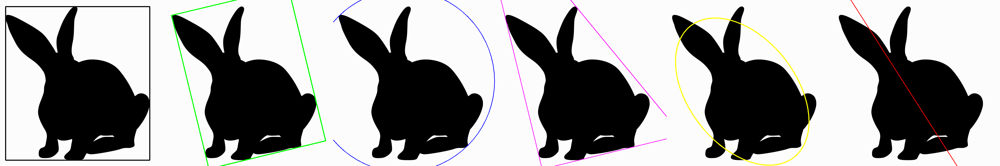

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

srcimg = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/rabbit inv.jpg')
img1 = srcimg.copy()
img2 = srcimg.copy()
img3 = srcimg.copy()
img4 = srcimg.copy()
img5 = srcimg.copy()
img6 = srcimg.copy()

imgray = cv2.cvtColor(srcimg, cv2.COLOR_BGR2GRAY)
ret, cntr_threshold = cv2.threshold(imgray, 127,255,cv2.THRESH_BINARY_INV)

# 컨투어 찾기
contours, hr = cv2.findContours(cntr_threshold, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour = contours[0]

# 감싸는 사각형 표시(검정색)
x,y,w,h = cv2.boundingRect(contour)
cv2.rectangle(img1, (x,y), (x+w, y+h), (0,0,0), 3)

# 최소한의 사각형 표시(초록색)
rect = cv2.minAreaRect(contour)
box = cv2.boxPoints(rect)   # 중심점과 각도를 4개의 꼭지점 좌표로 변환
box = np.int64(box)          # 정수로 변환 (np.int0 대신 np.int64 사용)
cv2.drawContours(img2, [box], -1, (0,255,0), 3)

# 최소한의 원 표시(파랑색)
(x_c,y_c), radius = cv2.minEnclosingCircle(contour)
cv2.circle(img3, (int(x_c), int(y_c)), int(radius), (255,0,0), 2)

# 최소한의 삼각형 표시(분홍색)
ret, tri = cv2.minEnclosingTriangle(contour)
cv2.polylines(img4, [np.int32(tri)], True, (255,0,255), 2)

# 최소한의 타원 표시(노랑색)
ellipse = cv2.fitEllipse(contour)
cv2.ellipse(img5, ellipse, (0,255,255), 3)

# 중심점 통과하는 직선 표시(빨강색)
[vx,vy,x_l,y_l] = cv2.fitLine(contour, cv2.DIST_L2,0,0.01,0.01)
cols,rows = img6.shape[:2]

# 1차원 numpy 배열 요소를 python scalar 값으로 추출
vx_val = vx.item()
vy_val = vy.item()
x_val = x_l.item()
y_val = y_l.item()

# 좌표 값을 정수형으로 변환하여 cv2.line에 전달
pt1 = (0, int(0 - x_val * (vy_val / vx_val) + y_val))
pt2 = (cols - 1, int((cols - 1 - x_val) * (vy_val / vx_val) + y_val))
cv2.line(img6, pt1, pt2, (0,0,255), 2)

image_frame = np.hstack([img1,img2,img3,img4,img5,img6])
cv2_imshow(image_frame)

# 02 이미지 모멘트(Moment)


# 02.1 컨투어와 모멘트로 넓이와 둘레 계산

Index 0 area:110889
Index 1 area:91199
Index 2 area:82027
Index 3 area:65732
Index 4 area:65820
Index 5 area:48460
Index 6 area:75555
Index 7 area:84144
Index 8 area:87582


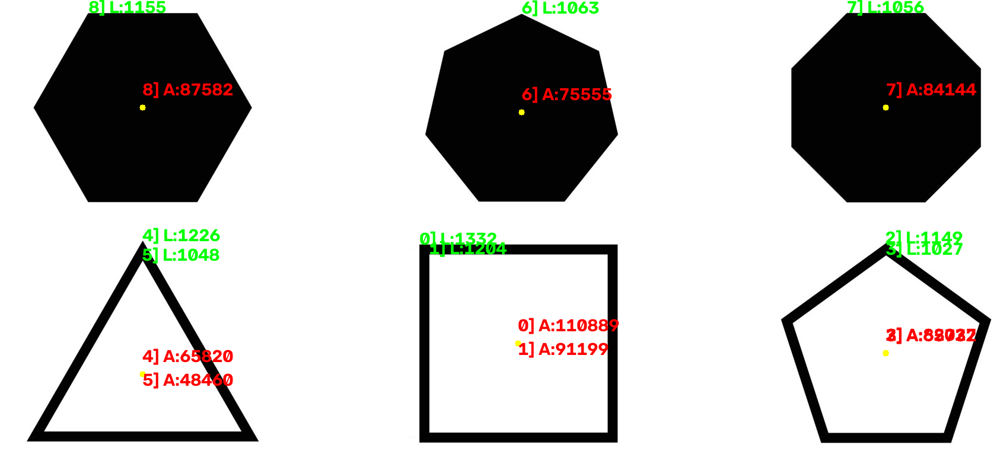

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/Hexagon_Shapes.jpg')
imgray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, imthres = cv2.threshold(imgray, 127, 255, cv2.THRESH_BINARY_INV)
#contours, hierarchy = cv2.findContours(imthres, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
contours, hierarchy = cv2.findContours(imthres, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

for idx, contour in enumerate(contours):
  moment = cv2.moments(contour)
  #중심점 찾기
  cx = int(moment['m10']/moment['m00'])
  cy = int(moment['m01']/moment['m00'])
  #영역 넓이
  area = moment['m00']
  length = cv2.arcLength(contour,True)
  cv2.circle(img,(cx,cy),5,(0,255,255),-1)
  cv2.putText(img,"{}] L:{:.0f}".format(idx,length), tuple(contour[0][0]), cv2.FONT_HERSHEY_DUPLEX,1,(0,255,0))

  #종속관계 확인 후 넓이와 둘레길이 표기
  pIdx = hierarchy[0][idx][3]
  pMoment = cv2.moments(contours[pIdx])
  pcy = int(pMoment['m01']/pMoment['m00'])

  if (pIdx != -1) and (pcy == cy):
    cv2.putText(img,"{}] A:{:.0f}".format(idx,area),(cx,cy+20), cv2.FONT_HERSHEY_DUPLEX,1,(0,0,255))
  else:
    cv2.putText(img,"{}] A:{:.0f}".format(idx,area),(cx,cy-20), cv2.FONT_HERSHEY_DUPLEX,1,(0,0,255))

  print("Index {} area:{:.0f}".format(idx, cv2.contourArea(contour)))


cv2_imshow(img)

# 02.2 컨투어 단순화 1

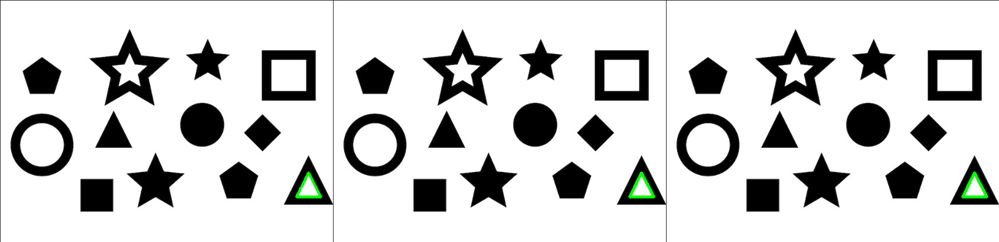

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes.jpg')
img2 = img1.copy()
img3 = img1.copy()

# 그레이스케일과 바이너리 스케일 변환
imgray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, th = cv2.threshold(imgray, 127, 255, cv2.THRESH_BINARY)

# 컨투어 찾기
contours, hierachy = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour = contours[0]

# 전체 둘레의 0.05로 오차 범위 지정
epsilon1 = 0.05 * cv2.arcLength(contour, True)
approx1 = cv2.approxPolyDP(contour, epsilon1, True)

# 전체 둘레의 0.09로 오차 범위 지정
epsilon2 = 0.09 * cv2.arcLength(contour, True)
approx2 = cv2.approxPolyDP(contour, epsilon2, True)


# 각각 컨투어 선 그리기
cv2.drawContours(img1, [contour], -1, (0,255,0), 3)
cv2.drawContours(img2, [approx1], -1, (0,255,0), 3)
cv2.drawContours(img3, [approx2], -1, (0,255,0), 3)

image_frame = np.hstack([img1,img2,img3])
cv2_imshow(image_frame)


# 02.3 컨투어 단순화 2


True True
검출된 볼록 선체 결함(defects)이 없습니다.


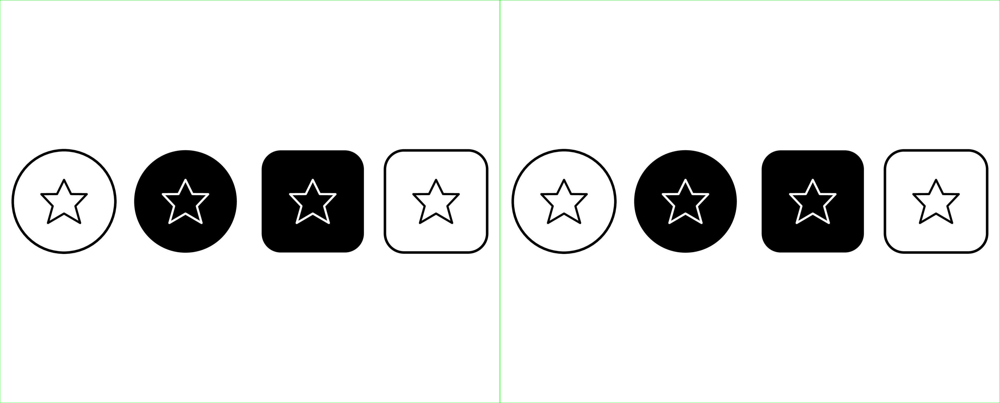

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/star-symbol-vector.jpg')
img2 = img1.copy()

gray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
ret, th = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
contours, heiarchy = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

cntr = contours[0]
cv2.drawContours(img1, [cntr], -1, (0, 255,0), 1)

# 볼록 선체 찾기(좌표 기준)와 그리기
hull = cv2.convexHull(cntr)
cv2.drawContours(img2, [hull], -1, (0,255,0), 1)
# 볼록 선체 만족 여부 확인
print(cv2.isContourConvex(cntr), cv2.isContourConvex(hull))

# 볼록 선체 찾기(인덱스 기준)
hull2 = cv2.convexHull(cntr, returnPoints=False)
# 볼록 선체 결함 찾기
defects = cv2.convexityDefects(cntr, hull2)

# 볼록 선체 결함 순회 (None 체크 예외 처리 추가)
if defects is not None:
    for i in range(defects.shape[0]):
        # 시작, 종료, 가장 먼 지점, 거리
        startP, endP, farthestP, distance = defects[i, 0]
        # 가장 먼 지점의 좌표 구하기
        farthest = tuple(cntr[farthestP][0])
        # 거리를 부동 소수점으로 변환
        dist = distance/256.0
        # 거리가 1보다 큰 경우
        if dist > 1 :
            # 빨강색 점 표시
            cv2.circle(img2, farthest, 3, (0,0,255), -1)
else:
    print("검출된 볼록 선체 결함(defects)이 없습니다.")

image_frame = np.hstack([img1,img2])
cv2_imshow(image_frame)

# 02.4 컨투어와 도형매칭


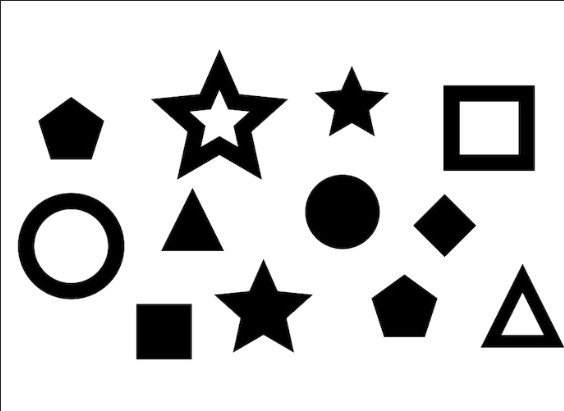

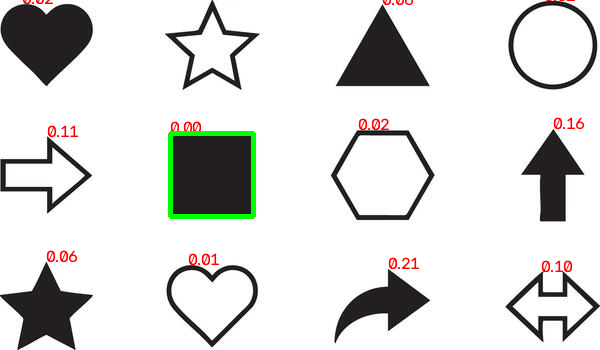

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


# 매칭을 위한 이미지 읽기
target = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes.jpg') # 매칭 대상
shapes = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes-vector.jpg') # 여러 도형


targetGray = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)
shapesGray = cv2.cvtColor(shapes, cv2.COLOR_BGR2GRAY)

ret, targetTh = cv2.threshold(targetGray, 127, 255, cv2.THRESH_BINARY_INV)
ret, shapesTh = cv2.threshold(shapesGray, 127, 255, cv2.THRESH_BINARY_INV)


cntrs_target, _ = cv2.findContours(targetTh, cv2.RETR_EXTERNAL, \
                                            cv2.CHAIN_APPROX_SIMPLE)
cntrs_shapes, _ = cv2.findContours(shapesTh, cv2.RETR_EXTERNAL, \
                                            cv2.CHAIN_APPROX_SIMPLE)


matchs = [] # 컨투어와 매칭 점수를 보관할 리스트
for contr in cntrs_shapes:
    # 대상 도형과 여러 도형 중 하나와 매칭 실행
    match = cv2.matchShapes(cntrs_target[0], contr, cv2.CONTOURS_MATCH_I2, 0.0)
    # 해당 도형의 매칭 점수와 컨투어를 쌍으로 저장
    matchs.append( (match, contr) )
    # 해당 도형의 컨투어 시작지점에 매칭 점수 표시
    cv2.putText(shapes, '%.2f'%match, tuple(contr[0][0]), cv2.FONT_HERSHEY_PLAIN, 1,(0,0,255),1 )

# 매칭 점수로 정렬
matchs.sort(key=lambda x : x[0])
# 가장 적은 매칭 점수를 얻는 도형의 컨투어에 선 그리기
cv2.drawContours(shapes, [matchs[0][1]], -1, (0,255,0), 3)
cv2_imshow(target)
cv2_imshow(shapes)

# 03 허프변환

# 03.1 허프 선 변환**

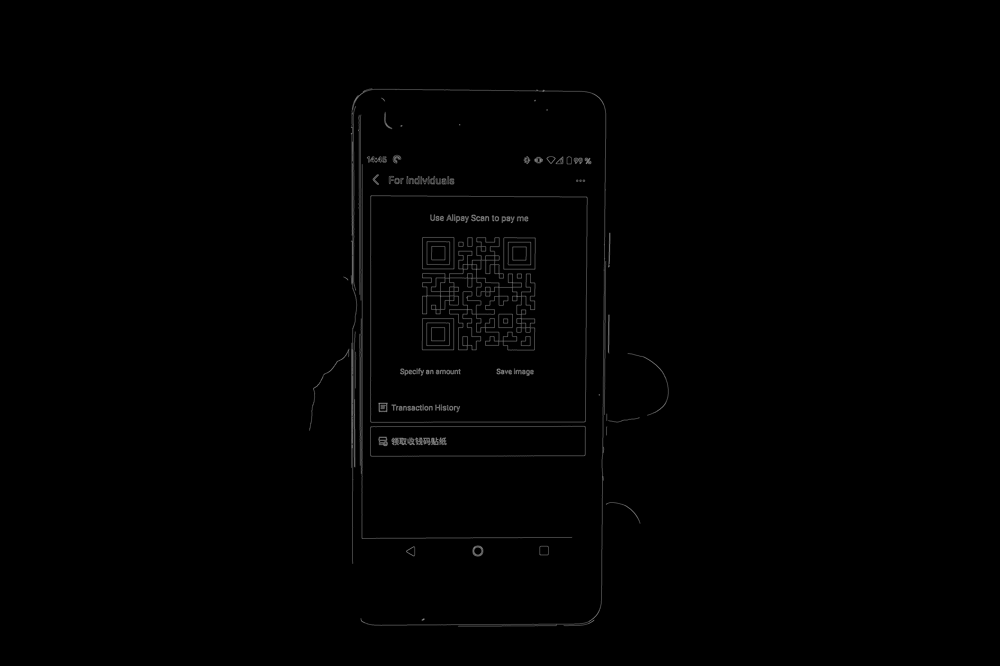

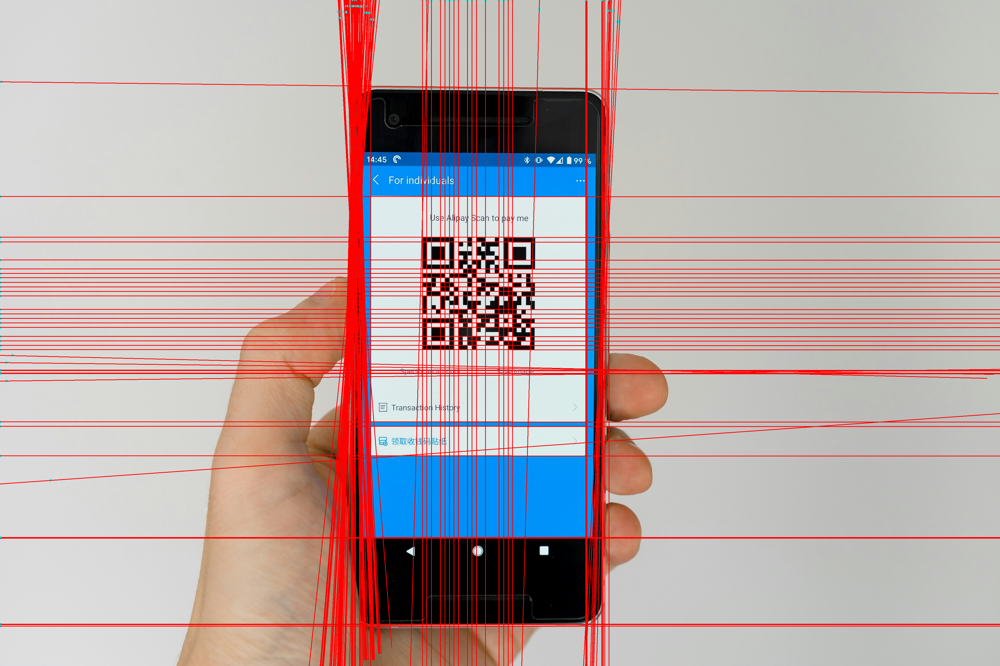

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/QRcode-unsplash.jpg')

img2 = img.copy()

height, width = img.shape[:2]

imgray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(imgray, 250, 400)
cv2_imshow(edges)

# 허프 선 검출, 직선으로 판단할 최소한의 점은 130개로 지정
lines = cv2.HoughLines(edges, 1, np.pi/180, 130)

for line in lines: # 검출된 모든 선
  for rho, theta in line:
    tx, ty = np.cos(theta), np.sin(theta) # x,y축에 대한 삼각비
    x0, y0 = tx*rho, ty*rho  #x, y 기준(절편) 좌표

    # 기준 좌표에 점 그리기 (정수형 변환 추가)
    cv2.circle(img2, (int(abs(x0)), int(abs(y0))), 5, (255,255,0), -1)

    # 직선 방정식으로 그리기 위한 시작점, 끝점 계산
    x1, y1 = int(x0 + width*(-ty)), int(y0 + height * tx)
    x2, y2 = int(x0 - width*(-ty)), int(y0 - height * tx)

    # 선그리기
    cv2.line(img2, (x1, y1), (x2, y2), (0,0,255), 2)

cv2_imshow(img2)

# 03.2 확률 허프 선 변환


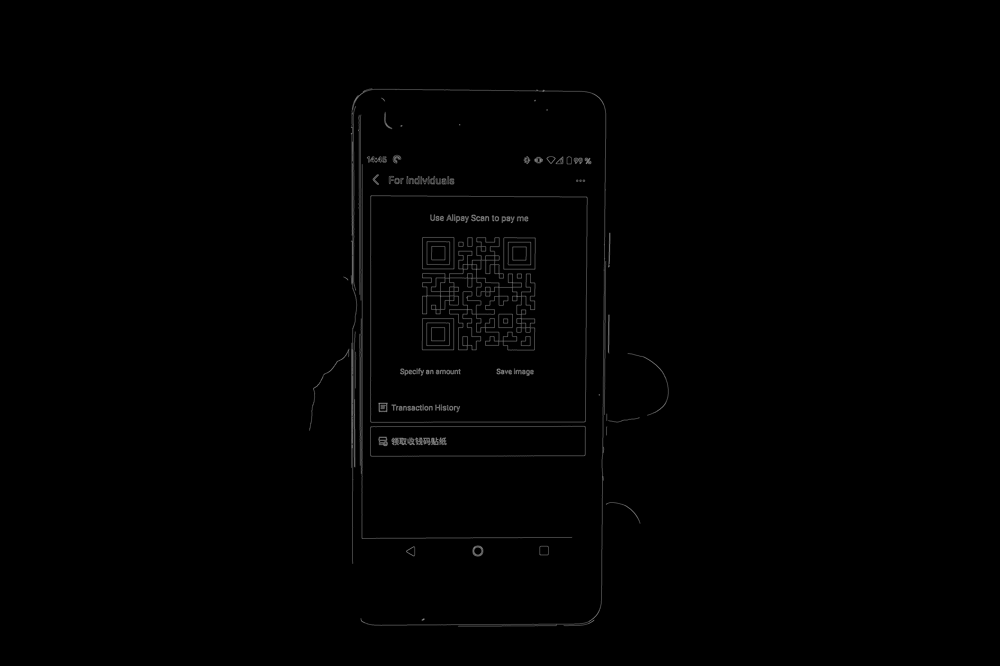

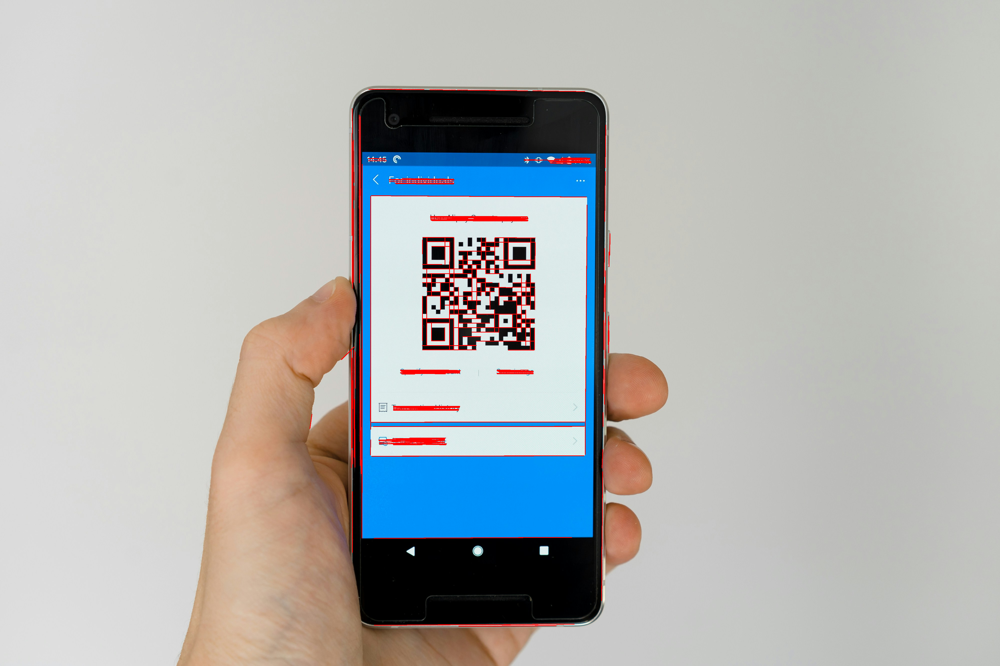

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/QRcode-unsplash.jpg')
img2 = img.copy()

# 그레이 스케일로 변환 및 캐니 엣지 검출
imgray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(imgray, 250, 400)
cv2_imshow(edges)

rho = 1
theta = np.pi/180
threshold = 60
min_line_length = 50
max_line_gap = 20

# 확률 허프 변환 적용
lines = cv2.HoughLinesP(edges, rho, theta, threshold, None, min_line_length, max_line_gap)

if lines is not None:
    for line in lines:
        # 검출된 선의 좌표가 1차원 배열 형태이므로 직접 언패킹
        x1, y1, x2, y2 = line
        cv2.line(img2, (x1, y1), (x2, y2), (0, 0, 255), 2)

cv2_imshow(img2)

# 03.3 허프 원 변환


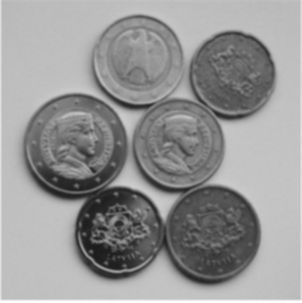

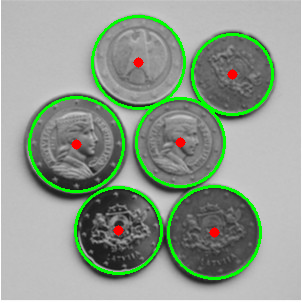

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/coins.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 노이즈 제거를 위한 가우시안 블러
blurimg = cv2.GaussianBlur(gray, (3,3), 0)
cv2_imshow(blurimg)

dp = 1
minDist = 20

circles = cv2.HoughCircles(blurimg, cv2.HOUGH_GRADIENT, dp, minDist, minRadius=10, maxRadius=100)
if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0,:]:
        # 원 둘레에 초록색 원 그리기
        cv2.circle(img,(i[0], i[1]), i[2], (0, 255, 0), 2)
        # 원 중심점에 빨강색 원 그리기
        cv2.circle(img, (i[0], i[1]), 2, (0,0,255), 6)

# 결과 출력
cv2_imshow(img)

# 04.1 거리 변환(Distance Transformation)


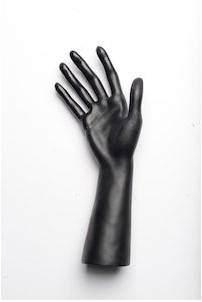

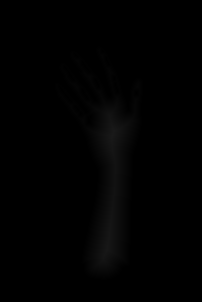

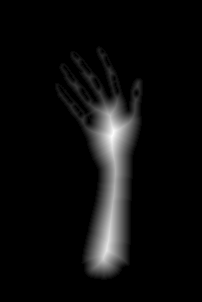

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/hand.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

dist_transform = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)

# dist_transform 함수를 사용하면 실수 타입(float32)의 이미지가 생성
#normalize 함수를 사용
result = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)

cv2_imshow(img)
cv2_imshow(dist_transform)
cv2_imshow(result)

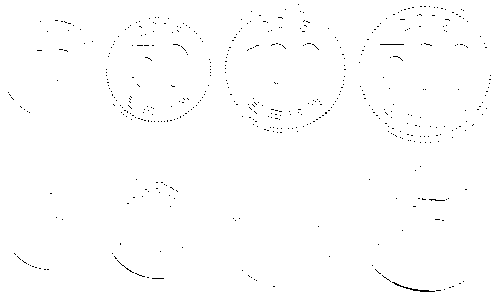

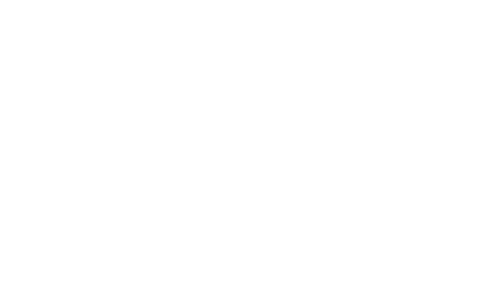

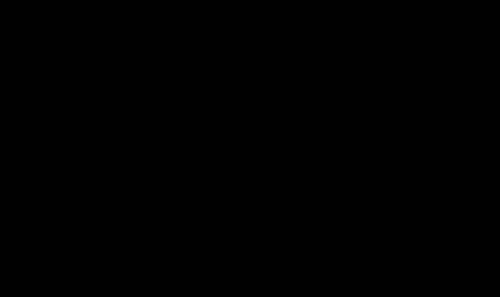

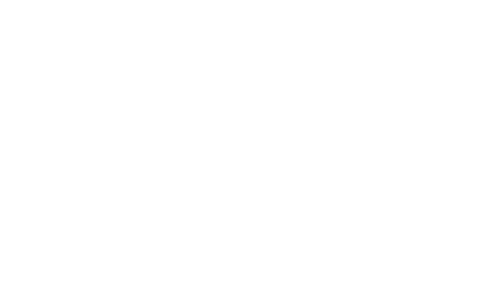

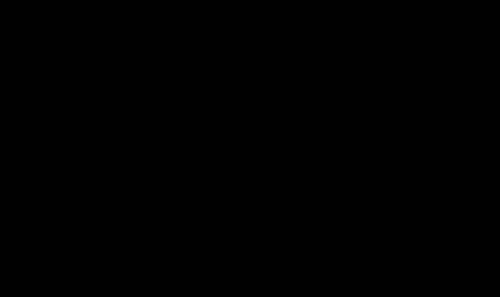

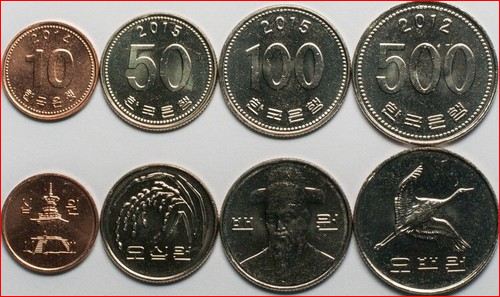

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/k-coin.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray,240,255,cv2.THRESH_BINARY_INV)
cv2_imshow(thresh)


#모폴로지를 사용해 노이즈나 구멍제거
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9,9))
sure_bg = cv2.dilate(thresh, kernel)
cv2_imshow(sure_bg)

#동전 중앙 부분을 검출하기 위해서 distance transform를 적용
dist_transform = cv2.distanceTransform(sure_bg, cv2.DIST_L2, 5)
result_dist_transform = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)
cv2_imshow(result_dist_transform)
# 이진화 스레시홀딩 적용
ret, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(),255, cv2.THRESH_BINARY)
cv2_imshow(sure_fg)

sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg,sure_fg)
cv2_imshow(unknown)

# 마커 라벨링
ret, markers = cv2.connectedComponents(sure_fg)

# 확실한 배경이 1이 되도록 모든 라벨에 1을 더함
markers = markers+1

# 확실하지 않은 구간을 0으로 처리
markers[unknown==255] = 0

markers = cv2.watershed(img, markers)

img[markers == -1] = [0, 0, 255]
img[markers == 1] = [100, 100, 100]

cv2_imshow(img)

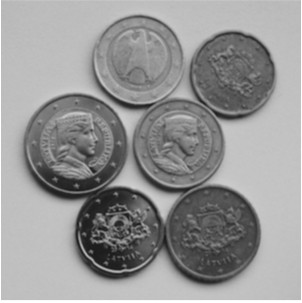

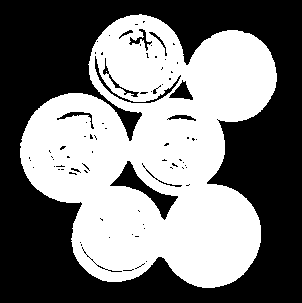

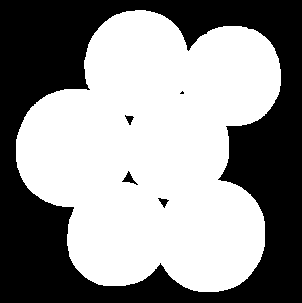

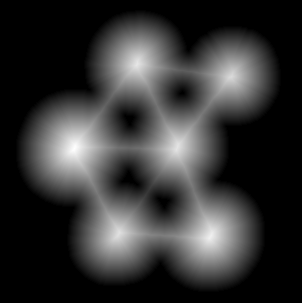

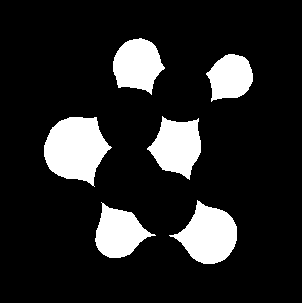

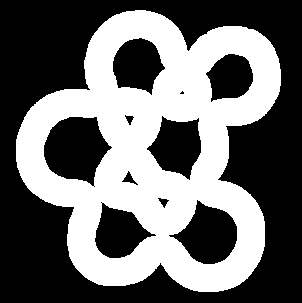

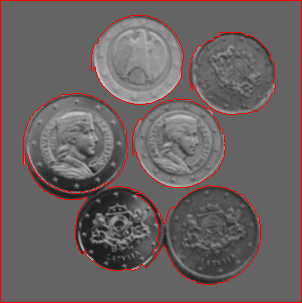

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/coins.jpg')
cv2_imshow(img)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray,160,255,cv2.THRESH_BINARY_INV)
cv2_imshow(thresh)


#모폴로지를 사용해 노이즈나 구멍제거
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9,9))
sure_bg = cv2.dilate(thresh, kernel)
cv2_imshow(sure_bg)

#동전 중앙 부분을 검출하기 위해서 distance transform를 적용
dist_transform = cv2.distanceTransform(sure_bg, cv2.DIST_L2, 5)
result_dist_transform = cv2.normalize(dist_transform, None, 255, 0, cv2.NORM_MINMAX, cv2.CV_8UC1)
cv2_imshow(result_dist_transform)

# 이진화 스레시홀딩 적용
ret, sure_fg = cv2.threshold(dist_transform, 0.5*dist_transform.max(),255, cv2.THRESH_BINARY)
cv2_imshow(sure_fg)

sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg,sure_fg)
cv2_imshow(unknown)

# 마커 라벨링
ret, markers = cv2.connectedComponents(sure_fg)

# 확실한 배경이 1이 되도록 모든 라벨에 1을 더함
markers = markers+1

# 확실하지 않은 구간을 0으로 처리
markers[unknown==255] = 0

markers = cv2.watershed(img, markers)

img[markers == -1] = [0, 0, 255]
img[markers == 1] = [100, 100, 100]

cv2_imshow(img)

# 실습8_이미지 매칭과 추적

# 01.1 평균 해시 매칭(Average Hash Matching)

In [ ]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('Gdrive',force_remount=True)

Mounted at Gdrive


# 01.1-1 이미지 해시 처리 하기

[[0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 0]
 [0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 0 0 0 0 1 1 1 1 0]]

3ffc3ffe7ffe7ffffe7ffe7ffc7ffc7ffc7ffe7ffe7ffe7ffe3ffe3ffe3f7e1e


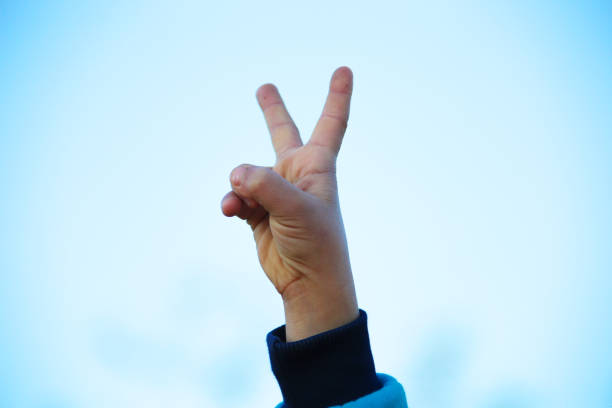

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/two hands.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 8x8 크기로 축소
gray = cv2.resize(gray, (16,16))
# 영상의 평균값 구하기
avg = gray.mean()
# 평균값을 기준으로 0과 1로 변환
bin = 1 * (gray > avg)
print(bin)
print("")

# 2진수 문자열을 16진수 문자열로 변환
dhash = []
for row in bin.tolist():
    s = ''.join([str(i) for i in row])
    dhash.append('%02x'%(int(s,2)))
dhash = ''.join(dhash)
print(dhash)

cv2_imshow(img)

# 01.1-2 해싱한 이미지 매칭하기

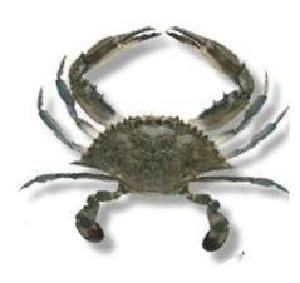

0.24609375


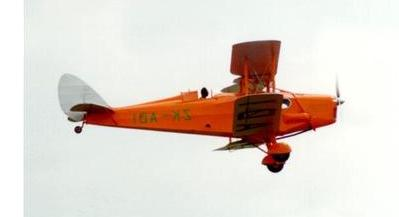

0.2265625


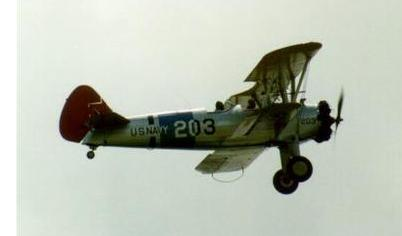

0.2265625


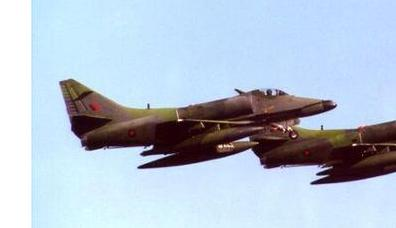

0.2421875


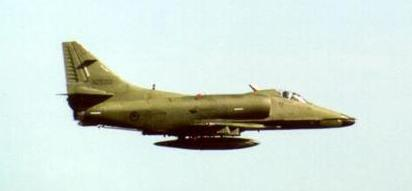

0.24609375


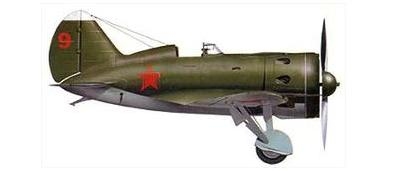

0.21875


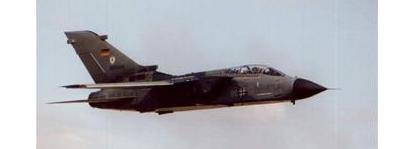

0.22265625


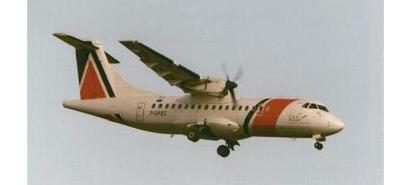

0.234375


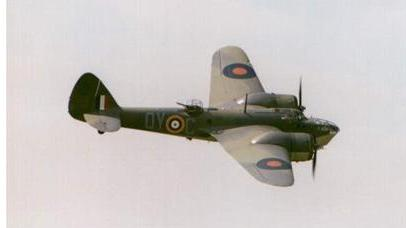

0.2265625


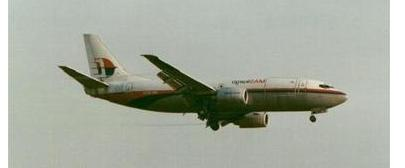

0.1953125


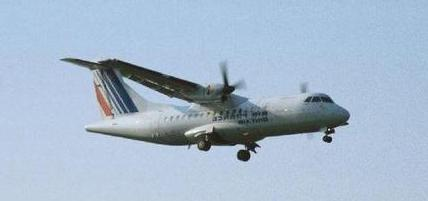

0.19140625


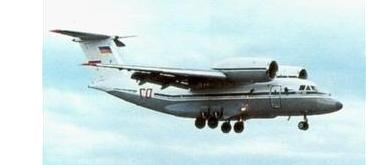

0.22265625


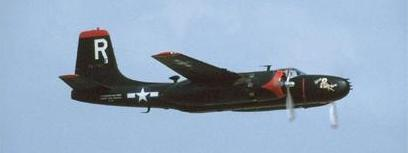

0.21484375


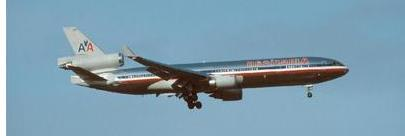

0.203125


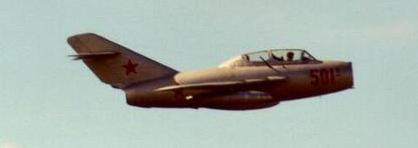

0.1953125


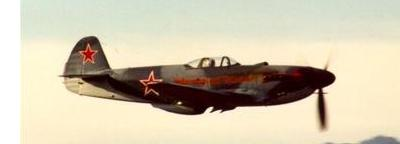

0.21875


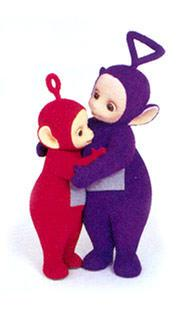

0.2421875


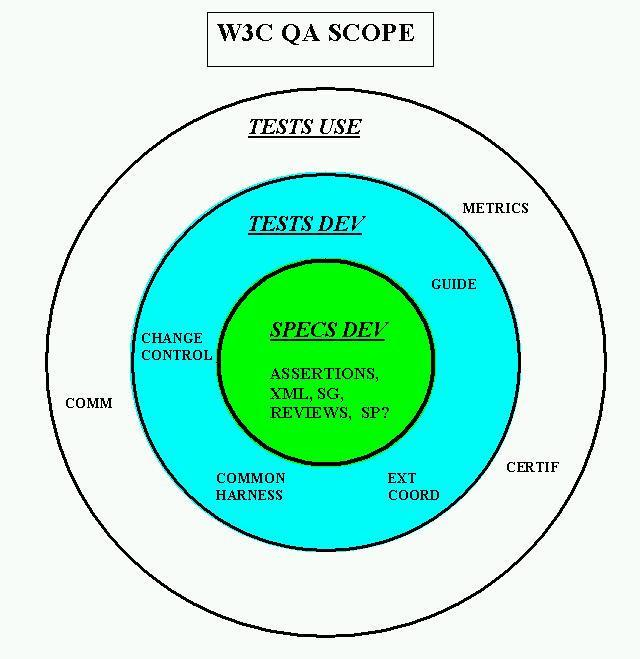

0.2421875


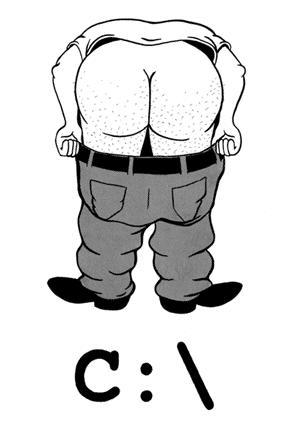

KeyboardInterrupt: 

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import glob

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/caltech-101/101_ObjectCategories/crab/image_0033.jpg')
search_dir = 'Gdrive/MyDrive//Colab Notebooks/photos/pic/caltech-101/101_ObjectCategories'

cv2_imshow(img)

# 이미지를 16x16 크기의 평균 해쉬로 변환
def img2hash(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (16, 16))
    avg = gray.mean()
    bi = 1 * (gray > avg)
    return bi

# 해밍거리 측정 함수
def hamming_distance(a, b):
    a = a.reshape(1,-1)
    b = b.reshape(1,-1)
    # 같은 자리의 값이 서로 다른 것들의 합
    distance = (a !=b).sum()
    return distance

# 기준 이미지 해쉬 구하기
query_hash = img2hash(img)

# 이미지 데이터 셋 디렉토리의 모든 영상 파일 경로
img_path = glob.glob(search_dir+'/**/*.jpg')

for path in img_path:
    img_comp = cv2.imread(path)
    # 데이터 셋 영상 한 개의 해시
    a_hash = img2hash(img_comp)
    # 해밍 거리 산출
    dst = hamming_distance(query_hash, a_hash)
    if dst/256 < 0.25: # 해밍거리 25% 이내만 출력
        print(dst/256)
        cv2_imshow(img_comp)

# 01.2 템플릿 매칭 (Template Matching)

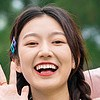

cv2.TM_CCOEFF_NORMED -0.4262162446975708 0.996106743812561 (77, 53) (379, 96)


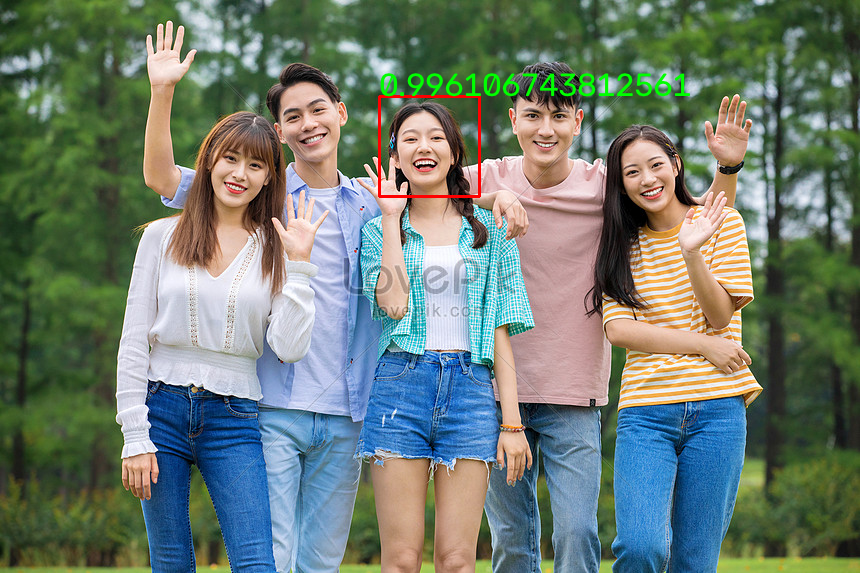

cv2.TM_CCORR_NORMED 0.5607537627220154 0.9990354180335999 (158, 372) (379, 96)


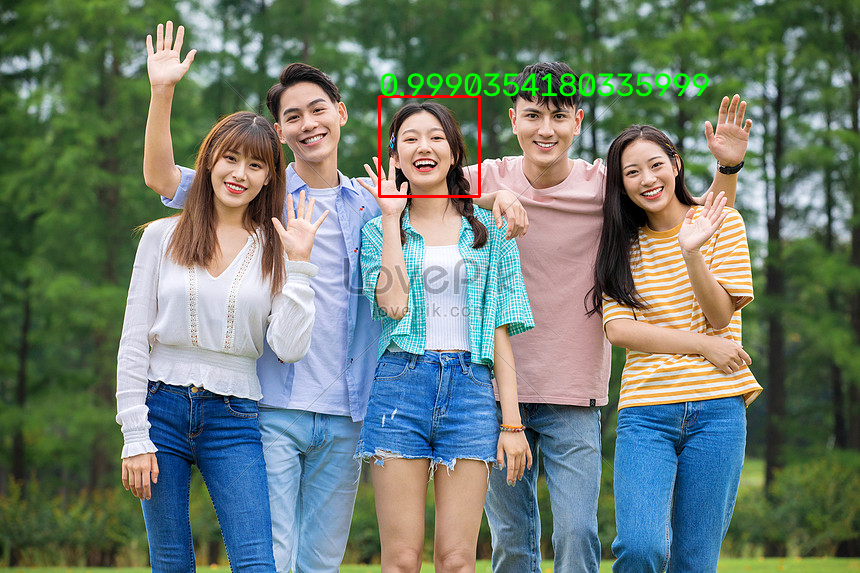

cv2.TM_SQDIFF_NORMED 0.0019304822199046612 1.0 (379, 96) (0, 154)


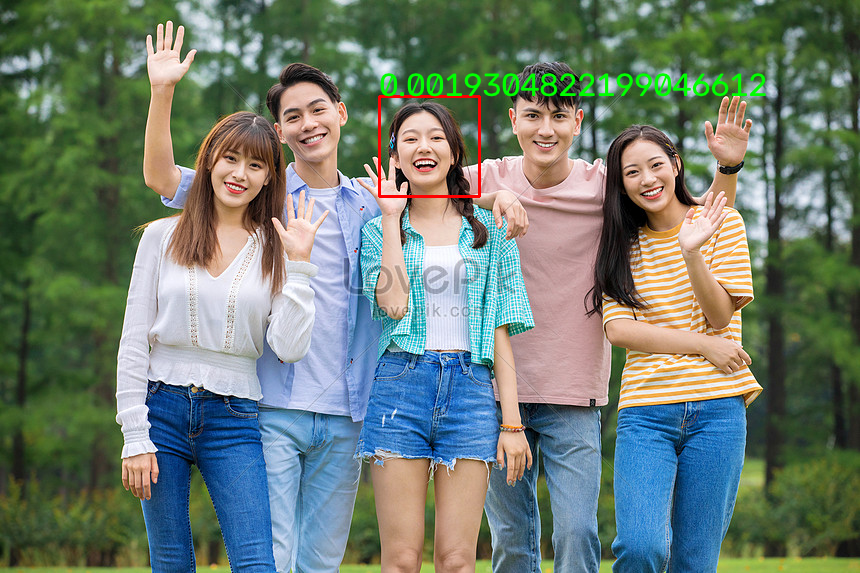

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples.jpg')
template = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/people_template.jpg')


th, tw = template.shape[:2]
cv2_imshow(template)

# 3가지 매칭 옵션
methods = ['cv2.TM_CCOEFF_NORMED', 'cv2.TM_CCORR_NORMED', 'cv2.TM_SQDIFF_NORMED']
for i, method_name in enumerate(methods):
    img_draw = img.copy()
    method = eval(method_name)
    # 템플릿 매칭
    res = cv2.matchTemplate(img, template, method)
    # 최대, 최소값과 그 좌표 구하기
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
    print(method_name, min_val, max_val, min_loc, max_loc)

    # TM_SQDIFF의 경우 최소값이 좋은 매칭, 나머지는 그 반대
    if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
        top_left = min_loc
        match_val = min_val
    else:
        top_left = max_loc
        match_val = max_val
    # 매칭 좌표 구해서 사각형 표시
    bottom_right = (top_left[0] + tw, top_left[1] + th)
    cv2.rectangle(img_draw, top_left, bottom_right, (0,0,255),2)
    # 매칭 포인트 표시
    cv2.putText(img_draw, str(match_val), top_left, \
                cv2.FONT_HERSHEY_PLAIN, 2,(0,255,0), 1, cv2.LINE_AA)
    cv2_imshow(img_draw)

# 01.3 복수 템플릿 매칭

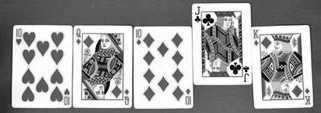

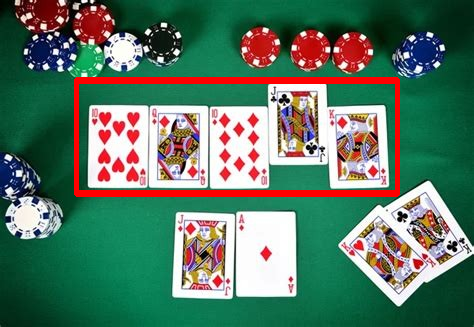

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/poker.jpeg')
template = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/card_template.jpg',cv2.IMREAD_GRAYSCALE)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

w, h = template.shape[::-1]
res = cv2.matchTemplate(gray,template,cv2.TM_CCOEFF_NORMED)
threshold = 0.8
loc = np.where( res >= threshold)
for pt in zip(*loc[::-1]):
    cv2.rectangle(img, pt, (pt[0] + w, pt[1] + h), (0,0,255), 2)

cv2_imshow(template)
cv2_imshow(img)

# 02 이미지의 특징

# 02.1 해리스 코너 검출 (Harris Corner Detection)


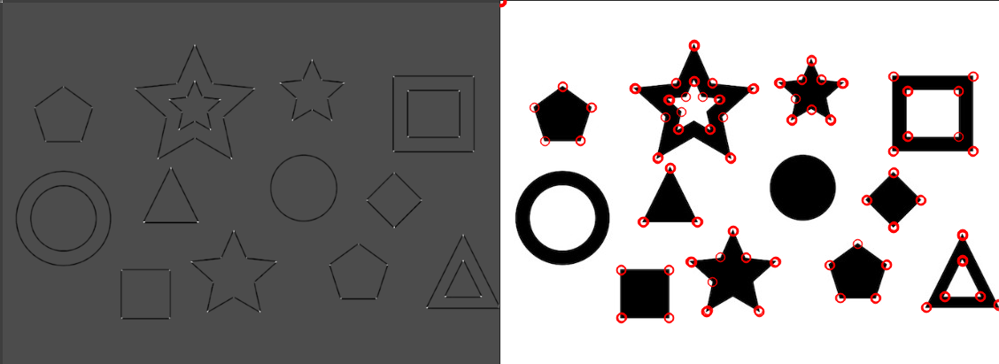

In [ ]:
import cv2
import numpy as np

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/300x200namsantower5.jpg')
img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 해리스 코너 검출
corner = cv2.cornerHarris(gray, 2, 3, 0.04)
# 변화량 결과의 최대값 10% 이상의 좌표 구하기
coord = np.where(corner > 0.1* corner.max())
coord = np.stack((coord[1], coord[0]), axis=-1)

# 코너 좌표에 동그리미 그리기
for x, y in coord:
    cv2.circle(img, (x,y), 5, (0,0,255), 1, cv2.LINE_AA)

# 변화량을 영상으로 표현하기 위해서 0~255로 정규화
corner_norm = cv2.normalize(corner, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
# 화면에 출력
corner_norm = cv2.cvtColor(corner_norm, cv2.COLOR_GRAY2BGR)
merged = np.hstack((corner_norm, img))
cv2_imshow( merged)

# 02.2 시-토마시 검출 (Shi & Tomasi Detection)

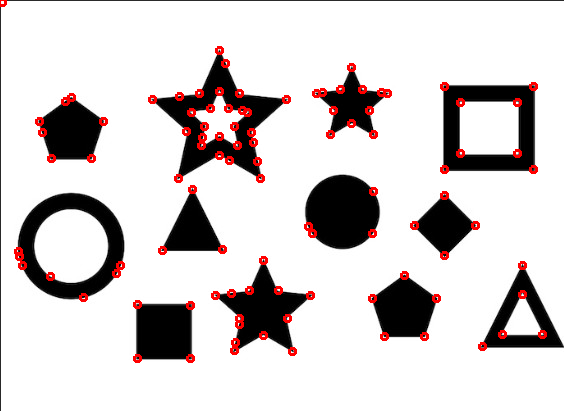

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
corners = cv2.goodFeaturesToTrack(gray, 100, 0.01, 5, blockSize=3, useHarrisDetector=False, k=0.03)

for i in corners:
    # float32 형태의 좌표를 정수형(int) 튜플로 변환하여 전달
    cv2.circle(img, tuple(map(int, i[0])), 3, (0, 0, 255), 2)

cv2_imshow(img)

# 02.3 FAST(Features from Accelerated Segment Test)


Threshold:  10
nonmaxSuppression:  True
neighborhood:  2
Total Keypoints with nonmaxSuppression:  599


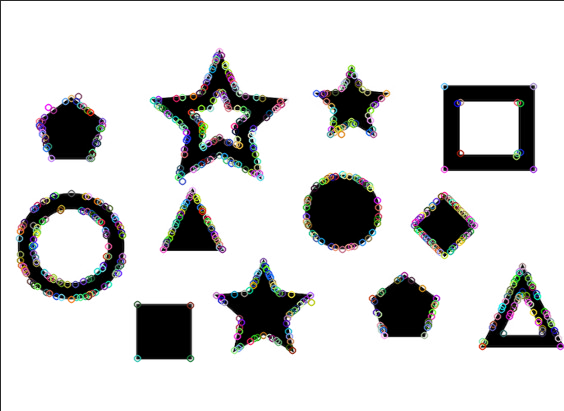

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/shapes.jpg')

fast = cv2.FastFeatureDetector_create()

fast.setThreshold(10)

kp = fast.detect(img,None)
result=cv2.drawKeypoints(img,kp,None)


print("Threshold: ", fast.getThreshold())
print("nonmaxSuppression: ", fast.getNonmaxSuppression())
print("neighborhood: ", fast.getType())
print("Total Keypoints with nonmaxSuppression: ", len(kp))

cv2_imshow(result)

# 03 얼굴 추적(Haar Cascades)


In [30]:
from IPython.display import HTML
HTML('<iframe height="400" src="https://www.youtube.com/embed/hPCTwxF0qf4" frameborder="0" allow="accelerometer; autoplay; encrypted-media; gyroscope; picture-in-picture" allowfullscreen></iframe>')

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


# 03.1 얼굴 검출

In [ ]:
!pip uninstall -y opencv-python opencv-contrib-python
!pip install opencv-python opencv-contrib-python

In [31]:
#구글 드라이브 마운트 하기
from google.colab import drive
drive.mount('Gdrive',force_remount=True)

Mounted at Gdrive


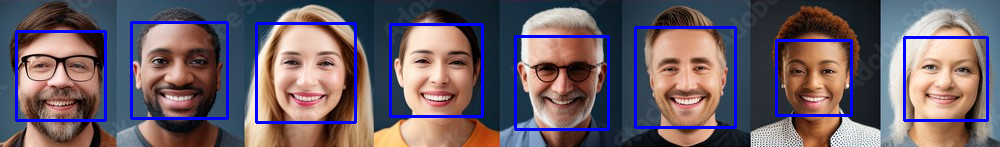

In [41]:
import numpy as np
import cv2
import urllib.request
from google.colab.patches import cv2_imshow

# Haar Cascade XML 파일을 공식 레포지토리에서 다운로드
xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml'
xml_path = 'haarcascade_frontalface_default.xml'
urllib.request.urlretrieve(xml_url, xml_path)

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples-faces02.jpg')
if img is None:
    img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples-faces01.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 다운로드한 로컬 XML 파일 경로로 분류기 생성
face_cascade = cv2.CascadeClassifier(xml_path)

faces = face_cascade.detectMultiScale(gray, 1.3, 3)

for (x,y,w,h) in faces:
     cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)

cv2_imshow(img)

# 03.2 눈 검출

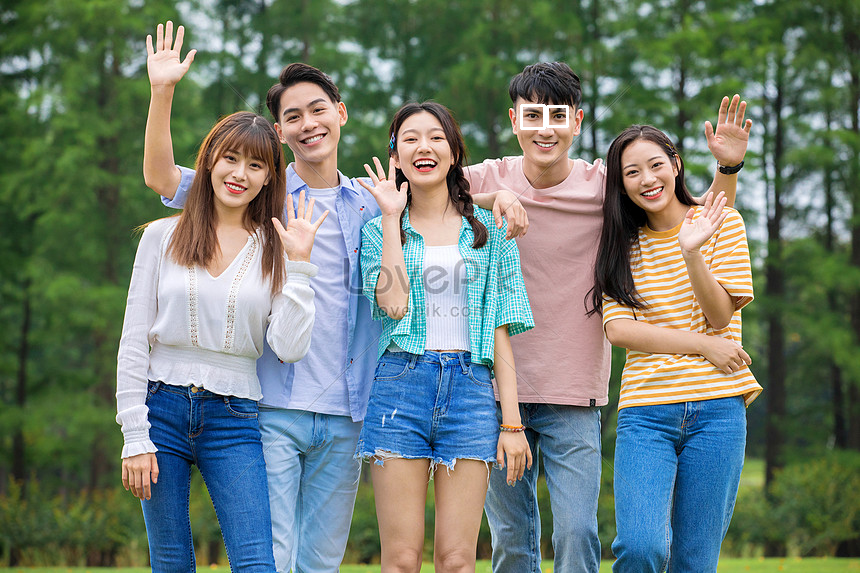

In [42]:
import numpy as np
import cv2
import urllib.request
from google.colab.patches import cv2_imshow

# 공식 저장소에서 눈 검출 XML 파일 다운로드
eye_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_eye.xml'
eye_xml_path = 'haarcascade_eye.xml'
urllib.request.urlretrieve(eye_xml_url, eye_xml_path)

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 다운로드한 로컬 XML 파일을 사용하여 분류기 생성
eye_cascade = cv2.CascadeClassifier(eye_xml_path)
eyes = eye_cascade.detectMultiScale(gray, 1.3, 1)

for (x,y,w,h) in eyes:
  cv2.rectangle(img,(x,y),(x+w,y+h),(255,255,255),2)

cv2_imshow(img)

# 03.3 얼굴과 눈 검출

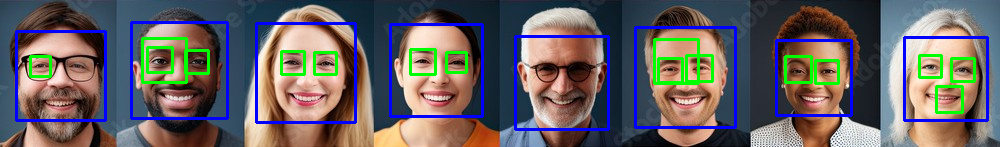

In [43]:
import numpy as np
import cv2
import urllib.request
from google.colab.patches import cv2_imshow

# Haar Cascade XML 파일 다운로드 경로 설정 및 다운로드
face_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml'
eye_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_eye.xml'

face_xml_path = 'haarcascade_frontalface_default.xml'
eye_xml_path = 'haarcascade_eye.xml'

urllib.request.urlretrieve(face_xml_url, face_xml_path)
urllib.request.urlretrieve(eye_xml_url, eye_xml_path)

# 실제 존재하는 드라이브 경로 이미지 불러오기
img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples-faces02.jpg')
if img is None:
    img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples-faces01.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 다운로드한 로컬 XML 파일을 사용하여 분류기 생성
face_cascade = cv2.CascadeClassifier(face_xml_path)
eye_cascade = cv2.CascadeClassifier(eye_xml_path)

faces = face_cascade.detectMultiScale(gray, 1.3, 4)
for (x,y,w,h) in faces:
    cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img[y:y+h, x:x+w]
    eyes = eye_cascade.detectMultiScale(roi_gray, 1.3, 1)
    for (ex,ey,ew,eh) in eyes:
        cv2.rectangle(roi_color,(ex,ey),(ex+ew,ey+eh),(0,255,0),2)

cv2_imshow(img)

# 03.4 웃는 입 검출

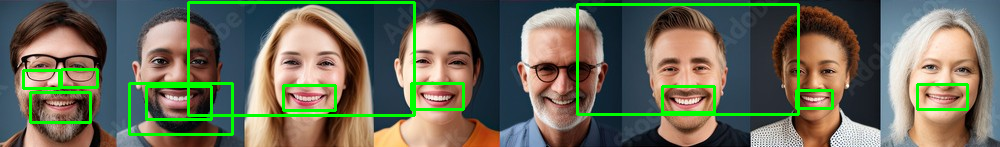

In [47]:
import numpy as np
import cv2
import urllib.request
from google.colab.patches import cv2_imshow

# 공식 저장소에서 웃음 검출 XML 파일 다운로드
smile_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_smile.xml'
smile_xml_path = 'haarcascade_smile.xml'
urllib.request.urlretrieve(smile_xml_url, smile_xml_path)

# 이미지 불러오기 및 그레이스케일 변환
img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples-faces02.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 다운로드한 로컬 XML 파일을 사용하여 분류기 생성
smile_cascade = cv2.CascadeClassifier(smile_xml_path)
smiles = smile_cascade.detectMultiScale(gray, 1.3, 2)

for (x,y,w,h) in smiles:
     cv2.rectangle(img,(x,y),(x+w,y+h),(0,255,0),2)

cv2_imshow(img)

# 03.5 얼굴과 웃는 입 검출

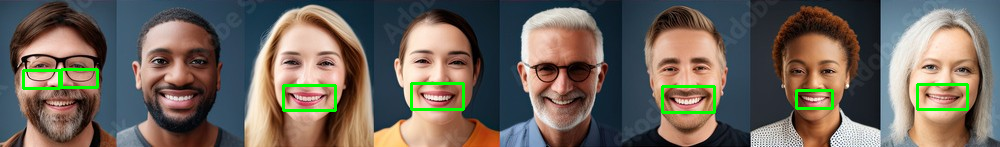

In [49]:
import numpy as np
import cv2
import urllib.request
from google.colab.patches import cv2_imshow

# 공식 저장소에서 얼굴 및 웃음 검출 XML 파일 다운로드
face_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml'
smile_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_smile.xml'

face_xml_path = 'haarcascade_frontalface_default.xml'
smile_xml_path = 'haarcascade_smile.xml'

urllib.request.urlretrieve(face_xml_url, face_xml_path)
urllib.request.urlretrieve(smile_xml_url, smile_xml_path)

img = cv2.imread('Gdrive/MyDrive//Colab Notebooks/photos/pic/peoples-faces02.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 다운로드한 로컬 XML 파일을 사용하여 분류기 생성
face_cascade = cv2.CascadeClassifier(face_xml_path)
smile_cascade = cv2.CascadeClassifier(smile_xml_path)

faces = face_cascade.detectMultiScale(gray, 1.3, 1)
smiles = smile_cascade.detectMultiScale(gray, 1.3, 2)

for (x,y,w,h) in faces:
  for (x_s,y_s,w_s,h_s) in smiles:
    if( (x <= x_s) and (y <= y_s) and ( x+w >= x_s+w_s) and ( y+h >= y_s+h_s)):
      cv2.rectangle(img, (x_s,y_s),(x_s+w_s,y_s+h_s),(0,255,0),2)

cv2_imshow(img)

# 04 코랩에서 비디오 카메라 사용하기
   04.1 코랩에서 제공하는 코드 불러오기
   Code Snippets 탭 선택 > 'Camera Capture' 검색 > 코드 삽입

In [50]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='myphoto.jpg', quality=0.9):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

In [51]:
from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

<IPython.core.display.Javascript object>

NotAllowedError: Permission denied


# 04.2 웹캠을 사용해 얼굴 인식하기

In [52]:
#필요한 라이브러리를 가져오기
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import cv2
import numpy as np
import PIL
import io
import html
import time

In [53]:
# 다른 확장자와 형식을 가진 이미지를 OpenCV 이미지 형식에 맞게 변환하는 함수
def js_to_image(js_reply):

  # base64 이미지로 디코드
  image_bytes = b64decode(js_reply.split(',')[1])
  # 넘파이 배열로 변환
  jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  # 넘파이 배열을 OpenCV BGR 이미지로 변환
  img = cv2.imdecode(jpg_as_np, flags=1)

  return img

In [59]:
# Haar Cascade Classifier 파일 다운로드 및 불러오기
import urllib.request
import cv2

# 공식 저장소에서 Haar Cascade XML 파일 다운로드
face_xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml'
face_xml_path = 'haarcascade_frontalface_default.xml'
urllib.request.urlretrieve(face_xml_url, face_xml_path)

# 다운로드한 로컬 XML 파일을 직접 사용하여 분류기 생성
face_cascade = cv2.CascadeClassifier(face_xml_path)

In [55]:
# 웹캠 연결하고 사진 찍는 함수 설정
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)

  # 사진 데이터 가져오기
  data = eval_js('takePhoto({})'.format(quality))
  # OpenCV 포멧으로 이미지 변환
  img = js_to_image(data)
  gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

  # Haar Cascade 함수를 사용해 얼굴 찾기
  faces = face_cascade.detectMultiScale(gray)
  for (x,y,w,h) in faces:
      img = cv2.rectangle(img,(x,y),(x+w,y+h),(255,0,0),2)

  #이미지 저장하기
  cv2.imwrite(filename, img)

  return filename

<IPython.core.display.Javascript object>

Saved to photo.jpg


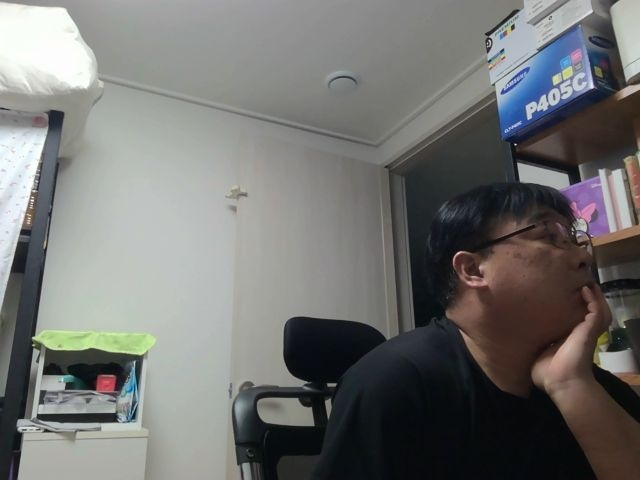

In [56]:
# 웹캠 카메라 연결 후 사진찍기
try:
  filename = take_photo('photo.jpg')
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

# 04.3 실시간 얼굴 추적

In [57]:
# JavaScript to properly create our live video stream using our webcam as input
def video_stream():
  js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;

    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
       stream.getVideoTracks()[0].stop();
       video.remove();
       div.remove();
       video = null;
       div = null;
       stream = null;
       imgElement = null;
       captureCanvas = null;
       labelElement = null;
    }

    function onAnimationFrame() {
      if (!shutdown) {
        window.requestAnimationFrame(onAnimationFrame);
      }
      if (pendingResolve) {
        var result = "";
        if (!shutdown) {
          captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
          result = captureCanvas.toDataURL('image/jpeg', 0.8)
        }
        var lp = pendingResolve;
        pendingResolve = null;
        lp(result);
      }
    }

    async function createDom() {
      if (div !== null) {
        return stream;
      }

      div = document.createElement('div');
      div.style.border = '2px solid black';
      div.style.padding = '3px';
      div.style.width = '100%';
      div.style.maxWidth = '600px';
      document.body.appendChild(div);

      const modelOut = document.createElement('div');
      modelOut.innerHTML = "<span>Status:</span>";
      labelElement = document.createElement('span');
      labelElement.innerText = 'No data';
      labelElement.style.fontWeight = 'bold';
      modelOut.appendChild(labelElement);
      div.appendChild(modelOut);

      video = document.createElement('video');
      video.style.display = 'block';
      video.width = div.clientWidth - 6;
      video.setAttribute('playsinline', '');
      video.onclick = () => { shutdown = true; };
      stream = await navigator.mediaDevices.getUserMedia(
          {video: { facingMode: "environment"}});
      div.appendChild(video);

      imgElement = document.createElement('img');
      imgElement.style.position = 'absolute';
      imgElement.style.zIndex = 1;
      imgElement.onclick = () => { shutdown = true; };
      div.appendChild(imgElement);

      const instruction = document.createElement('div');
      instruction.innerHTML =
          '<span style="color: red; font-weight: bold;">' +
          'When finished, click here or on the video to stop this demo</span>';
      div.appendChild(instruction);
      instruction.onclick = () => { shutdown = true; };

      video.srcObject = stream;
      await video.play();

      captureCanvas = document.createElement('canvas');
      captureCanvas.width = 640; //video.videoWidth;
      captureCanvas.height = 480; //video.videoHeight;
      window.requestAnimationFrame(onAnimationFrame);

      return stream;
    }
    async function stream_frame(label, imgData) {
      if (shutdown) {
        removeDom();
        shutdown = false;
        return '';
      }

      var preCreate = Date.now();
      stream = await createDom();

      var preShow = Date.now();
      if (label != "") {
        labelElement.innerHTML = label;
      }

      if (imgData != "") {
        var videoRect = video.getClientRects()[0];
        imgElement.style.top = videoRect.top + "px";
        imgElement.style.left = videoRect.left + "px";
        imgElement.style.width = videoRect.width + "px";
        imgElement.style.height = videoRect.height + "px";
        imgElement.src = imgData;
      }

      var preCapture = Date.now();
      var result = await new Promise(function(resolve, reject) {
        pendingResolve = resolve;
      });
      shutdown = false;

      return {'create': preShow - preCreate,
              'show': preCapture - preShow,
              'capture': Date.now() - preCapture,
              'img': result};
    }
    ''')

  display(js)

def bbox_to_bytes(bbox_array):
  # convert array into PIL image
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
  iobuf = io.BytesIO()
  # format bbox into png for return
  bbox_PIL.save(iobuf, format='png')
  # format return string
  bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))

  return bbox_bytes

def video_frame(label, bbox):
  data = eval_js('stream_frame("{}", "{}")'.format(label, bbox))
  return data

In [58]:
# start streaming video from webcam
video_stream()
# label for video
label_html = 'Capturing...'
# initialze bounding box to empty
bbox = ''
count = 0
while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break

    # convert JS response to OpenCV Image
    img = js_to_image(js_reply["img"])

    # create transparent overlay for bounding box
    bbox_array = np.zeros([480,640,4], dtype=np.uint8)

    # grayscale image for face detection
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # get face region coordinates
    faces = face_cascade.detectMultiScale(gray)
    # get face bounding box for overlay
    for (x,y,w,h) in faces:
      bbox_array = cv2.rectangle(bbox_array,(x,y),(x+w,y+h),(255,0,0),2)

    bbox_array[:,:,3] = (bbox_array.max(axis = 2) > 0 ).astype(int) * 255
    # convert overlay of bbox into bytes
    bbox_bytes = bbox_to_bytes(bbox_array)
    # update bbox so next frame gets new overlay
    bbox = bbox_bytes

<IPython.core.display.Javascript object>

/tmp/ipykernel_19480/2498818427.py:135: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
